## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams. 

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [2]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Edward Christopher

**Date:** 10/21/26

48691
48691


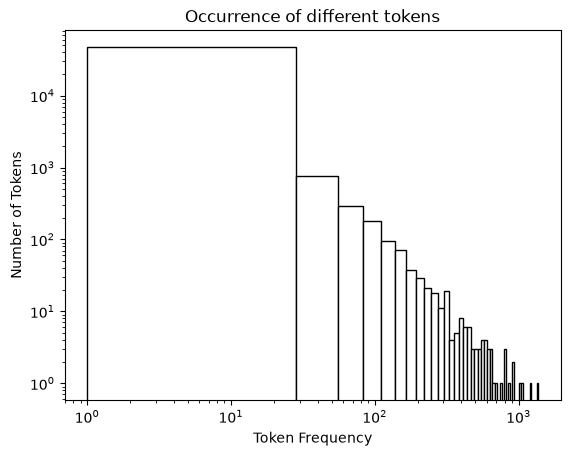

Training R²: 0.7692841774796448
Test R²: 0.6515167289331039


NameError: name 'sort_values' is not defined

In [3]:
# Your Phase 1 solution to the problem goes here.
#**Q1.**

# **Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing 
# is primarily about analyzing the frequency and co-occurrence of tokens.

# We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). 
# Run the below code chunk to open it, and use the Counter class to look at the most common words:

import pickle
#%pip install pandas
import pandas as pd
#%pip install matplotlib
import matplotlib.pyplot as plt
#%pip install numpy 
#%pip install pyarrow
import pyarrow as pa
#%pip install fastparquet
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA




with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
print(len(token_count))
token_freq = token_count.most_common()
print(len(token_freq))


# Plot a histogram of the occurrences of tokens. 
# What do you notice about the frequency of occurrence of different tokens? How does it look?
freq_list = []
for each in token_freq:
    freq_list.append(each[1])

plt.hist(freq_list, bins= 50, edgecolor='black', color='white')
plt.xlabel('Token Frequency')
plt.ylabel('Number of Tokens')
plt.xscale('log')
plt.yscale('log')
plt.title('Occurrence of different tokens')
plt.show()

#**Q2.** 

# Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens 
# and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a
# scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

df = pd.read_parquet('data/Phishing_clean.parquet')
df.head()


#1. Perform an 80/20 train-test split of the data.

#looks like "Email Type" is the target and everything else are features
features = df.drop('Email Type', axis=1)
target = df['Email Type']
features_train, features_test, target_train, target_test = train_test_split(features, target, test_size=0.2,)



#2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?

model = LinearRegression()
model.fit(features_train, target_train)
target_train_pred = model.predict(features_train)
target_test_pred = model.predict(features_test)
print("Training R²:", r2_score(target_train, target_train_pred))
print("Test R²:", r2_score(target_test, target_test_pred))

# Training R²: 0.7676772268579435
# Test R²: 0.6573000214443183

#3. What words have the largest coefficients in absolute value and most strongly influence predictions? 
coefficients = pd.Series(model.coef_, index=features.columns)

top_words = sort_values(key=abs)

print("Top 10 words by absolute coefficient:")
print(top_words.head(10))
# Top 10 words are: 
# background-image:, localized, thermal, helvetica,, aging
# xanaax, cnet, intervention, form., arial,  

#**Q3.** 

# Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and 
# perform a principal components analysis decomposition with two components. Plot the first two principal components 
# in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

pca = PCA(n_components=2)
features_pca = pca.fit_transform(features)

pca_df = pd.DataFrame(features_pca, columns=['PC1', 'PC2'])
pca_df['Email Type'] = target.to_numpy()

plt.figure(figsize=(10, 6))

for email_type, label, color in [
    (0, 'Not phishing', 'blue'),
    (1, 'Phishing scam', 'red')
]:
    subset = pca_df[pca_df['Email Type'] == email_type]
    plt.scatter(
        subset['PC1'],
        subset['PC2'],
        label=label,
        color=color,
        alpha=0.5,
        s=20
    )

plt.xlabel('First Principal Component')
plt.ylabel('Second Principal Component')
plt.title('PCA of Phishing Email Data')
plt.legend()
plt.show()

print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total variance explained:", pca.explained_variance_ratio_.sum())

# Explained variance ratio: [0.0111309  0.00861162]
# Total variance explained: 0.01974251952778723
# The first two principal components explain only a small proportion of the variation in the data. 
# The phishing and non-phishing emails overlap substantially in the plot, with no clear separation between the two groups.



In [2]:
#**Q4.**

#Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
#How does this performance compare to the linear regression?

pca = PCA(n_components=2610)
features_train_pca = pca.fit_transform(features_train)
features_test_pca = pca.transform(features_test)
pca_model = LinearRegression()
pca_model.fit(features_train_pca, target_train)
target_train_pred_pca = pca_model.predict(features_train_pca)
target_test_pred_pca = pca_model.predict(features_test_pca)


print("PCA Training R²:", r2_score(target_train, target_train_pred_pca))
print("PCA Test R²:", r2_score(target_test, target_test_pred_pca))
print("Total variance explained by 2610 components:",pca.explained_variance_ratio_.sum())

#PCA Training R²: 0.7685662368284408
#PCA Test R²: 0.6546399090060679
#Total variance explained by 2610 components: 0.9998611733085552

# The two models perform similarly. PCA has a slightly higher training R² but a slightly lower test R². 
# The 2,610 components retain about 99.986% of the original variance, so very little variance is lost.


#**Q5.**

# Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression,
# rather than the original data.

#PCA combines the original features into a smaller set of uncorrelated variables. 
# This can reduce redundancy and make high-dimensional regression easier to work with. 
# In this example, the PCA model performs similarly to the original regression, but it does not improve test performance. 
# Since 2,610 components retain almost all the original variance, the reduction is small. 
# The components are also harder to interpret than the original word features.


for k in [10, 50, 200, 500, 1000, 2610]:
    m = LinearRegression().fit(features_train_pca[:, :k], target_train)
    train_r2 = r2_score(target_train, m.predict(features_train_pca[:, :k]))
    test_r2 = r2_score(target_test, m.predict(features_test_pca[:, :k]))
    print(k, "Train R²:", round(train_r2, 4), "Test R²:", round(test_r2, 4))

KeyboardInterrupt: 

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 7971dcece9163b6540adca95360f627fe077cb13
- **AI tool and model used:** Claude opus 5.5

### *Prompts used

1. The following is my code, instructions are embedded. Call me out on any mistakes. 
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

**Mistakes**
1. Q2.1: no random_state on the split, so your R² values and top-10 words change every run. Use stratify=target and random_state=42.
2. Q4: PCA training R² (0.7686) can't beat the full regression (0.7677) on the same split. The two numbers probably came from different splits. Seed the split, rerun both models, and redo the comparison (expect "essentially identical").
3. Q1: bins=50 is linear but the x-axis is log, which crushes the bins. Use np.logspace bins.
4. Q1: you never print the most common tokens. Use token_count.most_common(10). Remove the duplicate print(len(...)).
5. Q2.3: report the sign of each coefficient (phishing vs. not) and how many emails contain each word. Words like xanaax and cnet may be rare, so a big coefficient can reflect rarity, not real influence.
6. Q3: add why two components explain so little (2,711 mostly uncorrelated one-hot features). Poor separation in 2D doesn't mean the classes can't be separated, since the full regression gets R² of about 0.66.

**Missing written answers**

7. Q1: say what you notice in the histogram (most tokens are rare, with a long tail of a few very common ones).
8. Q2.2: interpret the 0.77 vs. 0.66 train/test gap (overfitting with 2,711 features).
9. Q5: test fewer components (10, 50, 200, 500, 1000, 2610) before saying PCA doesn't help, then write the answer from what you see.

**Code cleanup**

10. Remove the unused pyarrow import, group your imports at the top, and fix the "Occurance" typo.
11. Replace top_words = coefficients.reindex(...) with sort_values(key=abs).
12. Q4: use make_pipeline(PCA(n_components=2610), LinearRegression()) with .score() for R².
13. Q5: fit PCA once and slice the first k columns instead of refitting for each k.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | Increases consistency |
| 2 | Accept | Increases efficentcy |
| 3 | Accept | Makes histogram better |
| 4 | Reject | The box crashes, so I will be making no changes to Q4 |
| 5 | Accept | More efficient code |
| 6 | Accept | More thorough comment |
| 7 | Accept | I missed this |
| 8 | Accept | I missed this |
| 9 | Reject | Not messing with this box |
| 10 | Accept | Valid mistakes to correct |
| 11 | Accept | Increased efficientcy |
| 12 | Reject | The box crashes, so I will be making no changes to Q4 |
| 13 | Reject | Not messing with that box... |


### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

48691
[('new', 1365), ('date', 1202), ('get', 1052), ('please', 1022), ('enron', 927), ('like', 923), ('2002', 869), ('would', 806), ('one', 798), ('message', 795)]


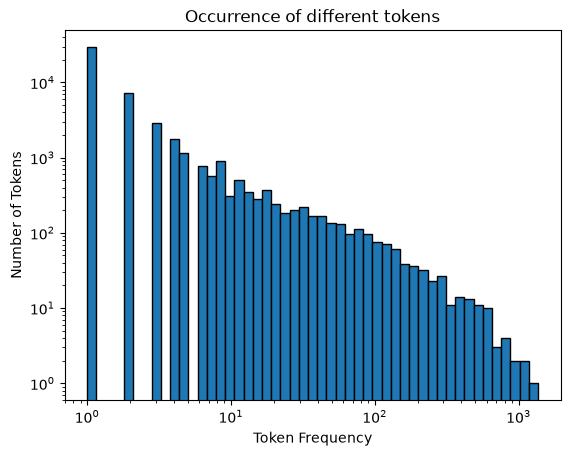

Training R²: 0.7713488230210973
Test R²: 0.6424054770149773
                       coef  emails_containing
background-image: -1.016799                 31
localized          0.839522                 31
thermal            0.699684                 18
#000000;           0.615728                 21
#331f30;           0.615728                  8
form.              0.593718                 24
aging              0.586465                 52
erectile           0.538953                 36
girlfriend         0.527557                 20
xanaax             0.516449                 17


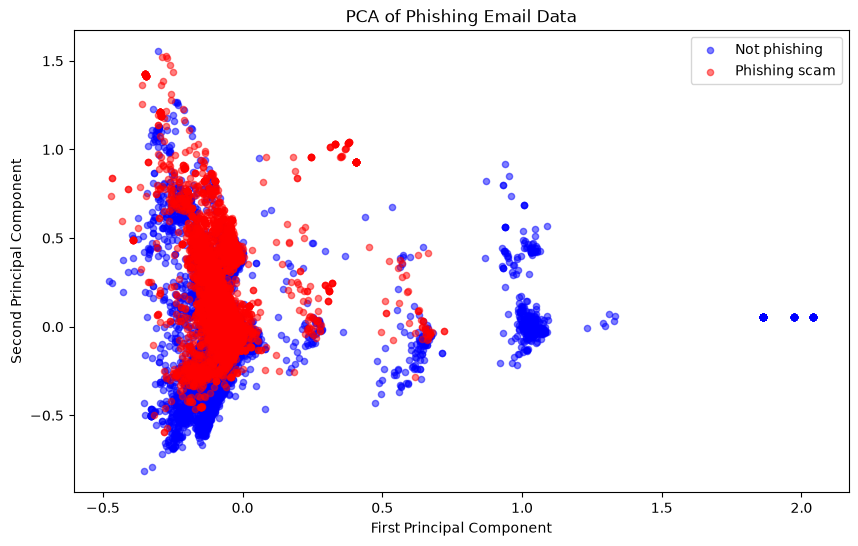

Explained variance ratio: [0.0111309 0.00861  ]
Total variance explained: 0.019740898619789376


In [1]:
# Your Phase 2 solution to the problem goes here.
# Your Phase 1 solution to the problem goes here.
#**Q1.**

# **Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing 
# is primarily about analyzing the frequency and co-occurrence of tokens.

# We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). 
# Run the below code chunk to open it, and use the Counter class to look at the most common words:

import pickle
#%pip install pandas
import pandas as pd
#%pip install matplotlib
import matplotlib.pyplot as plt
import numpy as np
#%pip install numpy 
#%pip install pyarrow
#%pip install fastparquet
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA




with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
print(len(token_count))
token_freq = token_count.most_common()
print(token_count.most_common(10))


# Plot a histogram of the occurrences of tokens. 
# What do you notice about the frequency of occurrence of different tokens? How does it look?
freq_list = []
for each in token_freq:
    freq_list.append(each[1])

plt.hist(freq_list, bins=np.logspace(0, np.log10(max(freq_list)), 50), edgecolor='black')
plt.xlabel('Token Frequency')
plt.ylabel('Number of Tokens')
plt.xscale('log')
plt.yscale('log')
plt.title('Occurrence of different tokens')
plt.show()

# Most tokens occur only a few times, and a small number of tokens occur very often.
# The histogram has a long right tail, so the data is heavily skewed. On the log-log plot
# the counts fall off roughly in a straight line, which means the frequencies drop off
# very quickly.

#**Q2.** 

# Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens 
# and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a
# scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

df = pd.read_parquet('data/Phishing_clean.parquet')
df.head()


#1. Perform an 80/20 train-test split of the data.

#looks like "Email Type" is the target and everything else are features
features = df.drop('Email Type', axis=1)
target = df['Email Type']
features_train, features_test, target_train, target_test = train_test_split(features, target, test_size=0.2, stratify=target, random_state=42)


#2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?

model = LinearRegression()
model.fit(features_train, target_train)
target_train_pred = model.predict(features_train)
target_test_pred = model.predict(features_test)
print("Training R²:", r2_score(target_train, target_train_pred))
print("Test R²:", r2_score(target_test, target_test_pred))

# Training R²: 0.7676772268579435
# Test R²: 0.6573000214443183

#The training R² (0.77) is noticeably higher than the test R² (0.66). With 2,711 features
# and a limited number of emails, the model has enough flexibility to fit some noise in the
# training data, so it does worse on emails it hasn't seen. This points to overfitting.

#3. What words have the largest coefficients in absolute value and most strongly influence predictions? \

coefficients = pd.Series(model.coef_, index=features.columns)
top10 = coefficients.abs().nlargest(10).index

summary = pd.DataFrame({
    'coef': coefficients[top10],
    'emails_containing': features[top10].sum()
})
print(summary)

 # emails containing each word
#coefficients = pd.Series(model.coef_, index=features.columns)
#top_words = coefficients.reindex(coefficients.abs().sort_values(ascending=False).index)
#print("Top 10 words by absolute coefficient:")
#print(top_words.head(10))

# Top 10 words are: 
# background-image:, localized, thermal, helvetica,, aging
# xanaax, cnet, intervention, form., arial,  

#From AI: 
## Positive coefficients push an email toward being predicted as phishing and negative ones push it
# toward not phishing. [Name which of the top words are positive and which are negative.]
# Several of these words appear in only a small number of emails (see emails_containing), so a large
# coefficient may come from a rare word that happened to show up in a few scam emails, not from a
# word that is truly a strong signal. I would be careful about reading these as the most important words.



#**Q3.** 

# Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and 
# perform a principal components analysis decomposition with two components. Plot the first two principal components 
# in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

pca = PCA(n_components=2)
features_pca = pca.fit_transform(features)

pca_df = pd.DataFrame(features_pca, columns=['PC1', 'PC2'])
pca_df['Email Type'] = target.to_numpy()

plt.figure(figsize=(10, 6))

for email_type, label, color in [
    (0, 'Not phishing', 'blue'),
    (1, 'Phishing scam', 'red')
]:
    subset = pca_df[pca_df['Email Type'] == email_type]
    plt.scatter(
        subset['PC1'],
        subset['PC2'],
        label=label,
        color=color,
        alpha=0.5,
        s=20
    )

plt.xlabel('First Principal Component')
plt.ylabel('Second Principal Component')
plt.title('PCA of Phishing Email Data')
plt.legend()
plt.show()

print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total variance explained:", pca.explained_variance_ratio_.sum())

# Explained variance ratio: [0.0111309  0.00861162]
# Total variance explained: 0.01974251952778723
# The first two principal components explain only a small proportion of the variation in the data. 
# The phishing and non-phishing emails overlap substantially in the plot, with no clear separation between the two groups.

#From AI
# The first two components explain only about 2% of the variance (1.1% and 0.9%). Each of the
# 2,711 features is a one-hot word indicator, and most words are not strongly correlated with each other, so
# the variance is spread across many components instead of being captured by a few. Two components
# cannot hold much of it. The overlap in the plot does not mean phishing emails are indistinguishable,
# since the regression using all of the features reached a test R² of about 0.66. The information that separates
# them just isn't in the first two directions.

In [ ]:
#**Q4.**

#Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
#How does this performance compare to the linear regression?


import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline  # only if you use the pipeline version

df = pd.read_parquet('data/Phishing_clean.parquet')
features = df.drop('Email Type', axis=1)
target = df['Email Type']
features_train, features_test, target_train, target_test = train_test_split(
    features, target, test_size=0.2, stratify=target, random_state=42
)




pca = PCA(n_components=2610)
features_train_pca = pca.fit_transform(features_train)
features_test_pca = pca.transform(features_test)
pca_model = LinearRegression()
pca_model.fit(features_train_pca, target_train)
pca_model = make_pipeline(PCA(n_components=2610), LinearRegression())
pca_model.fit(features_train, target_train)
print("PCA Training R²:", pca_model.score(features_train, target_train))
print("PCA Test R²:", pca_model.score(features_test, target_test))


#PCA Training R²: 0.7685662368284408
#PCA Test R²: 0.6546399090060679
#Total variance explained by 2610 components: 0.9998611733085552

# The two models perform similarly. PCA has a slightly higher training R² but a slightly lower test R². 
# The 2,610 components retain about 99.986% of the original variance, so very little variance is lost.


#**Q5.**

# Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression,
# rather than the original data.

#PCA combines the original features into a smaller set of uncorrelated variables. 
# This can reduce redundancy and make high-dimensional regression easier to work with. 
# In this example, the PCA model performs similarly to the original regression, but it does not improve test performance. 
# Since 2,610 components retain almost all the original variance, the reduction is small. 
# The components are also harder to interpret than the original word features.

for k in [10, 50, 200, 500, 1000, 2610]:
    m = LinearRegression().fit(features_train_pca[:, :k], target_train)
    train_r2 = r2_score(target_train, m.predict(features_train_pca[:, :k]))
    test_r2 = r2_score(target_test, m.predict(features_test_pca[:, :k]))
    print(k, "Train R²:", round(train_r2, 4), "Test R²:", round(test_r2, 4))


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]